# A 노트북 · 데이터·EDA·평가 틀

**담당:** A (이름: 이창민) · **중간 점검:** 11/29 · **최종 산출:** 4장(데이터), 2장(EDA) 글과 코드, GitHub Pages 배포(8단계)

**이 노트북에서 할 일**
1. 정제 보고서와 EDA 그림 (아래 기본 셀은 이미 돌아간다. 해석 글과 추가 그림을 더한다)
2. 평가 틀 확정: `ru.evaluate_scores`로 모든 방법을 같은 잣대로 평가한다 (함수는 `rfm_utils.py`에 있다)
3. 열린 결정 정리: 우편 요금 등 상품이 아닌 항목(StockCode가 POST 등)을 뺄지 → 빼면 `clean_transactions`를 고치고 `pytest` 통과 후 단톡방에 알린다
4. 용어는 "소비자"가 아니라 **"거래처 고객"** (README 확정 사항)

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rfm_utils as ru

clean, report = ru.clean_transactions(ru.load_raw())
inv = ru.invoice_table(clean)
datasets = {name: ru.make_dataset(inv, snap) for name, snap in ru.SNAPSHOTS.items()}
for name, snap in ru.SNAPSHOTS.items():
    ru.assert_no_leakage(inv, datasets[name], snap)   # 새 데이터셋을 만들 때마다 호출
{k: len(v) for k, v in datasets.items()}   # 기준일별 고객 수

{'S1': 4512, 'S2': 4908, 'S3': 5224}

## 1. 정제 보고서
정제 단계마다 몇 행이 빠졌는지 보여 준다. 본문에는 이 표를 넣고 "왜 그렇게 지웠는가"를 설명한다.

In [2]:
report

,step,rows
0,raw rows,1067371
1,removed: cancellations (invoice starts with C),19494
2,removed: missing customer id,242257
3,removed: quantity <= 0 or price <= 0,71
4,"removed: non-product lines (postage, fees, man...",2915
5,removed: exact duplicate rows,26055
6,clean rows,776579


## 2. EDA 기본 그림
월별 매출과 활동 고객 수, R·F·M 분포(로그 축), 상위 10% 고객의 매출 비중.

/var/folders/t_/nhlh57251lg1c99zkhn613fw0000gn/T/ipykernel_63102/1562245474.py:6: UserWarning: Glyph 50900 (\N{HANGUL SYLLABLE WEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/t_/nhlh57251lg1c99zkhn613fw0000gn/T/ipykernel_63102/1562245474.py:6: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/t_/nhlh57251lg1c99zkhn613fw0000gn/T/ipykernel_63102/1562245474.py:6: UserWarning: Glyph 47588 (\N{HANGUL SYLLABLE MAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/t_/nhlh57251lg1c99zkhn613fw0000gn/T/ipykernel_63102/1562245474.py:6: UserWarning: Glyph 52636 (\N{HANGUL SYLLABLE CUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/t_/nhlh57251lg1c99zkhn613fw0000gn/T/ipykernel_63102/1562245474.py:6: UserWarning: Glyph 54028 (\N{HANGUL SYLLABLE PA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show(

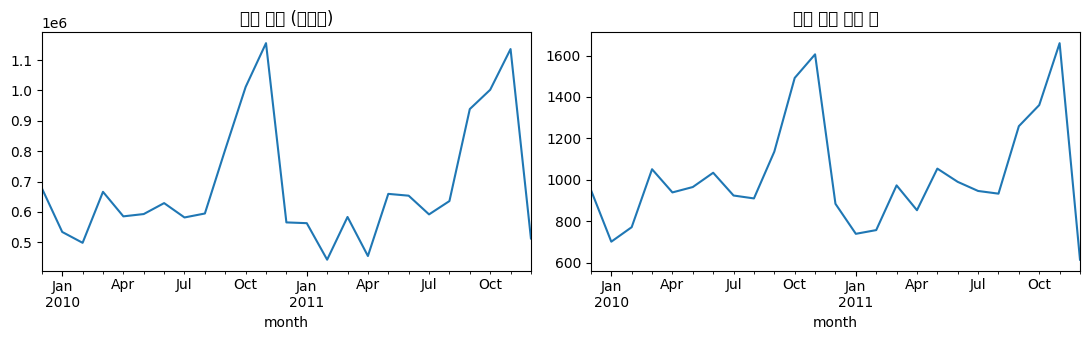

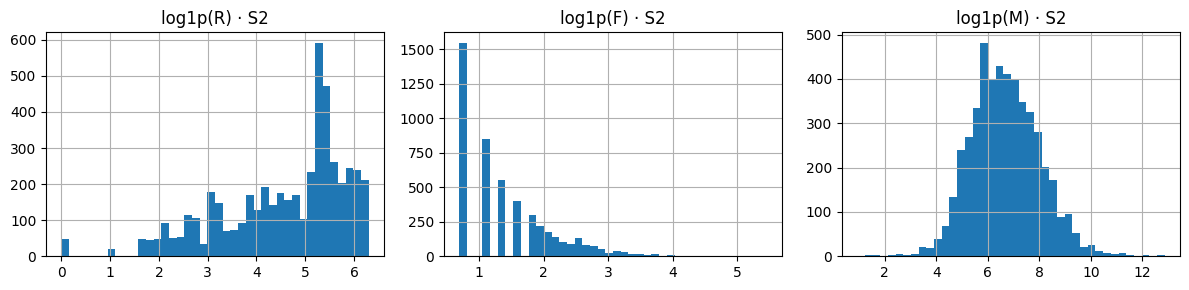

상위 10% 고객 매출 비중: 0.639


In [3]:
inv["month"] = inv["invoice_date"].dt.to_period("M")
monthly = inv.groupby("month").agg(revenue=("amount", "sum"), customers=("customer_id", "nunique"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
monthly["revenue"].plot(ax=ax[0], title="월별 매출 (파운드)")
monthly["customers"].plot(ax=ax[1], title="월별 활동 고객 수")
plt.tight_layout(); plt.show()

d = datasets["S2"]
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, col in zip(ax, ["R", "F", "M"]):
    np.log1p(d[col]).hist(ax=a, bins=40); a.set_title(f"log1p({col}) · S2")
plt.tight_layout(); plt.show()

total = inv.groupby("customer_id")["amount"].sum().sort_values(ascending=False)
print("상위 10% 고객 매출 비중:", round(total.head(int(len(total) * 0.1)).sum() / total.sum(), 3))

**TODO (A):** 위 그림 해석 3~5문장. 국가별 비중(영국 약 90%), 11~12월 계절성, 거래처 고객 특성(주문 중앙값 303파운드, 상품 한 줄 수량 중앙값 6개)을 "도매 성격"의 근거로 쓴다.

## 3. 평가 틀 점검
기준선("최근에 샀는가"만)을 세 기준일에서 평가한다. 다른 방법은 이 표와 같은 열로 비교된다.

In [4]:
rows = []
for name, d in datasets.items():
    res = ru.evaluate_scores(d["repurchase"], ru.baseline_recency_score(d))
    rows.append({"snapshot": name, **res})
pd.DataFrame(rows).round(3)

,snapshot,auc,pr_auc,base_rate,capture@10,precision@10,lift@10
0,S1,0.731,0.582,0.351,0.194,0.683,1.944
1,S2,0.774,0.587,0.329,0.202,0.666,2.021
2,S3,0.760,0.671,0.428,0.178,0.761,1.777


## 4. 다음 단계 (A)
- [ ] 정제 규칙 최종 결정 (POST 등 처리) 후 보고서 재생성
- [ ] 이득 곡선(gain/lift curve) 함수 작성: 입력은 `(y_true, score)`, B·C가 같이 쓴다
- [ ] 예산 시뮬레이션 틀: 상위 k%에 연락 시 비용·기대 매출 (가정은 표로 명시, 인과 주장 금지)
- [ ] 세 방법 비교표 취합 형식 정하기 (열: method, snapshot, auc, pr_auc, lift@10, capture@10)
- [ ] GitHub 저장소 만들고 GitHub Pages 배포 방법 확인 (8단계)

## 5. 세 방법 비교표 (outputs/ 읽기)
B·C가 저장한 `outputs/scores_*.csv`를 모두 읽어 같은 평가 함수로 비교한다. 파일이 새로 생기면 이 셀만 다시 실행하면 된다. 최종 비교는 **S3(테스트)** 기준.

In [5]:
scores = ru.load_score_frames()
rows = []
for (method, snap), g in scores.groupby(["method", "snapshot"]):
    name = [k for k, v in ru.SNAPSHOTS.items() if pd.Timestamp(v) == snap][0]
    d = datasets[name]
    s = g.set_index("customer_id")["score"].reindex(d.index)
    assert s.notna().all(), f"{method} {name}: missing customers"
    rows.append({"method": method, "snapshot": name, **ru.evaluate_scores(d["repurchase"], s)})
for name, d in datasets.items():   # 기준선도 같은 표에
    rows.append({"method": "recency_only", "snapshot": name, **ru.evaluate_scores(d["repurchase"], ru.baseline_recency_score(d))})
comparison = pd.DataFrame(rows).sort_values(["snapshot", "method"]).reset_index(drop=True)
comparison.round(3)

,method,snapshot,auc,pr_auc,base_rate,capture@10,precision@10,lift@10
0,recency_only,S1,0.731,0.582,0.351,0.194,0.683,1.944
1,rule_rfm,S1,0.782,0.669,0.351,0.241,0.847,2.411
2,logistic,S2,0.810,0.703,0.329,0.262,0.864,2.621
3,recency_only,S2,0.774,0.587,0.329,0.202,0.666,2.021
4,rule_rfm,S2,0.804,0.667,0.329,0.259,0.853,2.590
5,logistic,S3,0.785,0.743,0.428,0.205,0.877,2.050
6,recency_only,S3,0.760,0.671,0.428,0.178,0.761,1.777
7,rule_rfm,S3,0.782,0.723,0.428,0.210,0.900,2.104
